# NB7 — GRPO với reward kiểm chứng được (RLVR) (THƯỞNG, +8)

DPO học từ *cặp* sở thích có sẵn (ngoại tuyến). GRPO (DeepSeekMath, 2024; dùng trong
DeepSeek-R1) sinh **G câu trả lời cho mỗi câu hỏi**, chấm bằng hàm reward, rồi đẩy
xác suất các câu có reward cao hơn trung bình nhóm. Không cần mô hình reward hay
mô hình critic: với toán, reward là "đáp số đúng hay sai" (RLVR, *verifiable rewards*).

Notebook này chạy một vòng GRPO rất nhỏ để thấy cơ chế, **không** để đạt điểm cao.
T4: ~40 phút cho 60 bước với G=4.

**Dữ liệu:** `vuongtsc/vi-gsm8k-agentic` (MIT): 1.465 bài toán tiểu học viết mới bằng
tiếng Việt từ seed GSM8K, đáp số dạng số đã kiểm tra bằng chạy code. Bộ này chỉ có
split `train`, nên notebook tự chia cố định thành tập huấn luyện/kiểm tra. Các bài được lọc để mô hình yếu
giải sai, nên độ chính xác ban đầu của mô hình 4B có thể thấp: nếu cả G câu trả lời của một
câu hỏi đều sai thì advantage = 0 và câu hỏi đó không đóng góp gradient.

| | DPO (NB3) | GRPO (NB7) |
|---|---|---|
| Dữ liệu | cặp chosen/rejected cố định | chỉ cần câu hỏi + cách chấm |
| Sinh trong lúc huấn luyện | không | có (tự sinh, on-policy) |
| Reference / KL | bắt buộc (β) | tuỳ chọn; TRL mặc định `beta=0.0` |
| Chi phí | 2 forward / cặp | G lần sinh / câu hỏi |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lab22" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import unsloth  # noqa: F401
import torch

from lab22 import config as C
from lab22 import math_reward as MR
from lab22 import modeling as MD

assert torch.cuda.is_available()
assert C.SFT_MERGED.exists(), "Run NB1 first"
C.ensure_dirs()

BIG = C.COMPUTE_TIER == "BIGGPU"
N_TRAIN, N_TEST, MAX_STEPS, G = (1265, 200, 200, 8) if BIG else (400, 100, 60, 4)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


D:\Day22\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1023 21:01:23.768000 34036 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Unsloth: xformers is installed but cannot load with torch 2.10.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!


## 1. Dữ liệu + hàm reward

In [2]:
from datasets import load_dataset

INSTRUCTION = "Giải bài toán sau. Suy luận ngắn gọn, rồi kết thúc bằng dòng 'Đáp số: <số>'.\n\n"


def gold(answer: str) -> str:
    return answer.split("####")[-1].strip().replace(",", "")


def to_row(r):
    # vi-gsm8k-agentic stores the number in `final_answer`; GSM8K puts it after "####".
    ref = str(r["final_answer"]) if "final_answer" in r else gold(r["answer"])
    return {"prompt": [{"role": "user", "content": INSTRUCTION + r["question"]}], "answer": ref.strip()}


if C.GRPO_DATASET == "openai/gsm8k":
    gsm = load_dataset("openai/gsm8k", "main")
    train_raw, test_raw = gsm["train"].shuffle(seed=C.SEED), gsm["test"]
else:
    # Single split: hold out a fixed test slice before any training row is drawn.
    parts = load_dataset(C.GRPO_DATASET, split="train").shuffle(seed=C.SEED).train_test_split(
        test_size=N_TEST, seed=C.SEED
    )
    train_raw, test_raw = parts["train"], parts["test"]
cols = train_raw.column_names
train_ds = train_raw.select(range(min(N_TRAIN, len(train_raw)))).map(to_row, remove_columns=cols)
test_ds = test_raw.select(range(min(N_TEST, len(test_raw)))).map(to_row, remove_columns=cols)
assert not set(train_ds["prompt"][i][0]["content"] for i in range(len(train_ds))) & set(
    test_ds["prompt"][i][0]["content"] for i in range(len(test_ds))
), "GRPO train/test overlap"
print(f"{C.GRPO_DATASET}: train {len(train_ds)} · test {len(test_ds)}")

# Đọc số theo cả kiểu Việt ("1.440", "2,5") lẫn kiểu Anh ("1,440", "2.5"): xem lab22/math_reward.py.
correctness_reward, format_reward = MR.correctness_reward, MR.format_reward
assert MR.is_correct(MR.extract_answer("... vậy\nĐáp số: 1.250"), "1250")
assert MR.is_correct(MR.extract_answer("Đáp số: 2,5 kg"), "2.5")
assert correctness_reward([[{"content": "Đáp số: 7"}]], ["8"]) == [0.0]

Map: 100%|██████████| 100/100 [00:00<00:00, 2815.01 examples/s]


vuongtsc/vi-gsm8k-agentic: train 400 · test 100


## 2. Độ chính xác trước khi huấn luyện

In [3]:
def accuracy(model, tokenizer) -> float:
    prompts = [r["prompt"][0]["content"] for r in test_ds]
    outs = MD.generate(model, tokenizer, prompts, max_new_tokens=320, batch_size=1)
    return sum(MR.is_correct(MR.extract_answer(o), r["answer"]) for o, r in zip(outs, test_ds)) / len(test_ds)


model, tokenizer = MD.load_model(C.SFT_MERGED)
acc_before = accuracy(model, tokenizer)
print(f"test[{len(test_ds)}] accuracy before GRPO: {acc_before:.3f}")
model = MD.add_lora(model)

==((====))==  Unsloth 2026.10.7: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA GeForce RTX 3060. Num GPUs = 1. Max memory: 12.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.10.0+cu130. CUDA: 8.6. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights: 100%|██████████| 398/398 [00:11<00:00, 36.14it/s]
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (

test[100] accuracy before GRPO: 0.510


Unsloth 2026.10.7 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


## 3. GRPO

`per_device_train_batch_size × grad_accum` phải chia hết cho `num_generations` (G):
mỗi batch chứa trọn các nhóm G câu trả lời của cùng một câu hỏi.

In [4]:
from trl import GRPOConfig, GRPOTrainer

args = GRPOConfig(
    output_dir=str(C.ADAPTERS / "grpo-checkpoints"),
    per_device_train_batch_size=G,
    gradient_accumulation_steps=1,
    num_generations=G,
    max_completion_length=320,
    max_steps=MAX_STEPS,
    learning_rate=5e-6,
    warmup_steps=0.1,
    lr_scheduler_type="cosine",
    temperature=1.0,
    chat_template_kwargs=C.CHAT_TEMPLATE_KWARGS,
    logging_steps=5,
    save_strategy="no",
    optim="adamw_8bit",
    seed=C.SEED,
    report_to="none",
    **MD.precision_flags(),
)
trainer = GRPOTrainer(
    model=model,
    reward_funcs=[correctness_reward, format_reward],
    args=args,
    train_dataset=train_ds,
    processing_class=tokenizer,
)
trainer.train()

Unsloth: GRPO now defaults to TRL's loss_type = 'dapo' with beta = 0.0. Set loss_type = 'bnpo', beta = 0.001 for Unsloth's previous default.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 400 | Num Epochs = 1 | Total steps = 60
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 1 x 1) = 4
 "-____-"     Trainable parameters = 33,030,144 of 4,055,498,240 (0.81% trained)
Passing `generation_config` together with generation-related arguments=({'cache_implementation', 'pad_token_id'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / correctness_reward / mean,rewards / correctness_reward / std,rewards / format_reward / mean,rewards / format_reward / std
5,0.092640,0.550000,0.626723,274.400000,226.400000,302.200000,0.550000,235.850000,226.400000,245.800000,0.000000,0.300000,0.430940,0.250000,0.215470
10,0.053004,0.325000,0.521736,279.200000,236.000000,320.000000,0.700000,126.033334,108.000000,147.200000,0.000000,0.200000,0.400000,0.125000,0.150000
15,0.042027,1.300000,0.230940,232.150000,193.800000,267.800000,0.400000,104.150000,65.800000,139.800000,0.000000,1.000000,0.230940,0.300000,0.000000
20,0.036130,0.850000,0.538048,272.250000,232.000000,291.200000,0.550000,191.050000,168.000000,206.400000,0.000000,0.600000,0.400000,0.250000,0.157735
25,-0.046508,0.575000,0.511880,269.650000,207.000000,317.200000,0.400000,193.350000,143.000000,240.400000,0.000000,0.300000,0.430940,0.275000,0.165470
30,0.091144,0.900000,0.838249,273.150000,243.000000,320.000000,0.400000,249.500000,243.000000,254.800000,0.000000,0.600000,0.630940,0.300000,0.273205
35,0.038202,0.650000,0.157735,286.900000,245.000000,319.800000,0.450000,199.733334,181.000000,226.200000,0.000000,0.400000,0.000000,0.250000,0.157735
40,0.030692,1.125000,0.862996,274.400000,215.800000,315.800000,0.350000,253.383334,215.800000,277.200000,0.000000,0.800000,0.630940,0.325000,0.250000
45,0.061357,0.650000,0.571736,285.400000,256.400000,307.400000,0.500000,270.266669,256.400000,288.000000,0.000000,0.400000,0.400000,0.250000,0.200000
50,0.030544,0.725000,0.750000,299.050000,273.600000,312.600000,0.550000,217.100000,209.600000,226.600000,0.000000,0.500000,0.600000,0.225000,0.150000


Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_

TrainOutput(global_step=60, training_loss=0.034713653723398845, metrics={'train_runtime': 3613.4023, 'train_samples_per_second': 0.066, 'train_steps_per_second': 0.017, 'total_flos': 0.0, 'train_loss': 0.034713653723398845, 'epoch': 0.15})

## 4. Đường cong reward + độ chính xác sau huấn luyện (sản phẩm nộp `08-grpo-reward.png`)

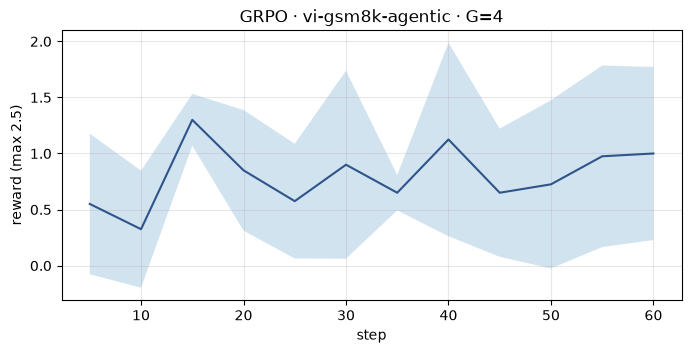

Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_

{'dataset': 'vuongtsc/vi-gsm8k-agentic', 'n_test': 100, 'steps': 60, 'num_generations': 4, 'acc_before': 0.51, 'acc_after': 0.49}


In [5]:
import json

import matplotlib.pyplot as plt
import pandas as pd

logs = pd.DataFrame([r for r in trainer.state.log_history if "reward" in r])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(logs["step"], logs["reward"], color="#2e548a", label="mean reward")
if "reward_std" in logs:
    ax.fill_between(logs["step"], logs["reward"] - logs["reward_std"], logs["reward"] + logs["reward_std"], alpha=0.2)
ax.set_xlabel("step")
ax.set_ylabel("reward (max 2.5)")
ax.set_title(f"GRPO · {C.GRPO_DATASET.split('/')[-1]} · G={G}")
ax.grid(True, alpha=0.3)
fig.savefig(C.SCREENSHOTS / "08-grpo-reward.png", dpi=120, bbox_inches="tight")
plt.show()

acc_after = accuracy(trainer.model, tokenizer)
trainer.model.save_pretrained(str(C.GRPO_ADAPTER))
result = {
    "dataset": C.GRPO_DATASET, "n_test": len(test_ds), "steps": MAX_STEPS,
    "num_generations": G, "acc_before": acc_before, "acc_after": acc_after,
}
(C.GRPO_ADAPTER / "grpo_metrics.json").write_text(json.dumps(result, indent=2))
print(result)

## 5. Câu hỏi

1. Reward tăng nhanh nhất ở thành phần nào: định dạng hay tính đúng? Đó có phải "khai thác lỗ hổng reward (reward hacking)" không?
2. Với N_TEST=100, chênh lệch độ chính xác bao nhiêu mới vượt nhiễu? (sai số chuẩn ≈ √(p(1−p)/n)).
3. So `acc_before` với GSM8K (tiếng Anh) của SFT ở NB6: ngôn ngữ, độ khó, câu hỏi và cách chấm
   đều khác, nên con số nào đáng tin hơn cho câu hỏi "GRPO có giúp toán không"?